In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# 1. Load data
df= pd.read_excel('https://github.com/Apur52027/Dataset_ML/blob/main/BSMDD_v3_textcleaned%20-%2021K.xlsx?raw=true')

In [ ]:

DATA_PATH = 'https://github.com/Apur52027/Dataset_ML/blob/main/BSMDD_v3_textcleaned%20-%2021K.xlsx?raw=true'

df = pd.read_excel(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (21910, 2)


,text,label
0,মানসিক শারীরিকভাবে অসুস্থ ক্লান্ত পুরো জীবন শা...,1
1,দয়া সাথে থাকুন অত্যন্ত দীর্ঘ আপনাকে পড়তে উত্...,1
2,জানতাম সাথে ভুল লোক খারাপ জীবন কাটিয়েছে সম্পূ...,1
3,অনেটিভ ইংরেজি স্পিকারের অনুসরণ বিরক্তিকর অপ্রত...,1
4,অনেটিভ ইংরেজি স্পিকারের অনুসরণ বিরক্তিকর অপ্রত...,1



Columns:
['text', 'label']


In [ ]:
# ============================================================
# CELL 6 — DATA QUALITY
# ============================================================

# Ensure TEXT_COL and LABEL_COL are defined
# (These are typically set in an earlier cell like CkD_PgZD7g0-)
if 'TEXT_COL' not in globals():
    TEXT_COL = 'text'
if 'LABEL_COL' not in globals():
    LABEL_COL = 'label'

quality_report = pd.DataFrame({
    "Metric": [
        "Total samples",
        "Missing text",
        "Empty text",
        "Duplicate text",
        "Missing label",
        "Unique texts"
    ],
    "Count": [
        len(df),
        df[TEXT_COL].isna().sum(),
        (df[TEXT_COL].fillna("").astype(str).str.strip() == "").sum(),
        df[TEXT_COL].duplicated().sum(),
        df[LABEL_COL].isna().sum(),
        df[TEXT_COL].nunique()
    ]
})

display(quality_report)

,Metric,Count
0,Total samples,21910
1,Missing text,0
2,Empty text,0
3,Duplicate text,6
4,Missing label,0
5,Unique texts,21904


In [ ]:
import re

In [ ]:
# ============================================================
# CELL 8 — BANGLA TEXT NORMALIZATION
# ============================================================

BANGLA_RANGE = r"\u0980-\u09FF"

def normalize_bangla(text):

    text = str(text)

    # Unicode normalization
    import unicodedata
    text = unicodedata.normalize("NFC", text)

    # URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Mentions
    text = re.sub(r"@\w+", " ", text)

    # Hashtag symbol but retain word
    text = text.replace("#", " ")

    # English digits + Bengali digits
    text = re.sub(r"[0-9০-৯]+", " ", text)

    # Keep Bengali, English letters and whitespace
    text = re.sub(
        rf"[^{BANGLA_RANGE}A-Za-z\s]",
        " ",
        text
    )

    # Multiple spaces
    text = re.sub(r"\s+", " ", text)

    return text.strip()


df["clean_text"] = df[TEXT_COL].apply(normalize_bangla)

display(
    df[[TEXT_COL, "clean_text"]].head(10)
)

,text,clean_text
0,মানসিক শারীরিকভাবে অসুস্থ ক্লান্ত পুরো জীবন শা...,মানসিক শারীরিকভাবে অসুস্থ ক্লান্ত পুরো জীবন শা...
1,দয়া সাথে থাকুন অত্যন্ত দীর্ঘ আপনাকে পড়তে উত্...,দয়া সাথে থাকুন অত্যন্ত দীর্ঘ আপনাকে পড়তে উত্...
2,জানতাম সাথে ভুল লোক খারাপ জীবন কাটিয়েছে সম্পূ...,জানতাম সাথে ভুল লোক খারাপ জীবন কাটিয়েছে সম্পূ...
3,অনেটিভ ইংরেজি স্পিকারের অনুসরণ বিরক্তিকর অপ্রত...,অনেটিভ ইংরেজি স্পিকারের অনুসরণ বিরক্তিকর অপ্রত...
4,অনেটিভ ইংরেজি স্পিকারের অনুসরণ বিরক্তিকর অপ্রত...,অনেটিভ ইংরেজি স্পিকারের অনুসরণ বিরক্তিকর অপ্রত...
5,প্রথমে আপনাকে প্রশ্ন উপস্থাপন যাচ্ছি পারবেন দি...,প্রথমে আপনাকে প্রশ্ন উপস্থাপন যাচ্ছি পারবেন দি...
6,রেফারেন্সের বয়সী পুরুষ থাকার সাইক ওয়ার্ড বের...,রেফারেন্সের বয়সী পুরুষ থাকার সাইক ওয়ার্ড বের...
7,দৈর্ঘ্যের ক্ষমাপ্রার্থী বোঝানোর বের আলিঙ্গন বল...,দৈর্ঘ্যের ক্ষমাপ্রার্থী বোঝানোর বের আলিঙ্গন বল...
8,উপকারী সাব দয়া আপলোড পোস্ট সেরা জায়গা মোবাইল...,উপকারী সাব দয়া আপলোড পোস্ট সেরা জায়গা মোবাইল...
9,দীর্ঘ পোস্ট জীবনের সারসংক্ষেপ টাইম লাইনটি একটু...,দীর্ঘ পোস্ট জীবনের সারসংক্ষেপ টাইম লাইনটি একটু...


In [ ]:
import os

# ---------- 1.3 Pipeline (Continued) ----------

# Assuming 'df' is the global DataFrame with 'clean_text' column already processed.
# And 'TEXT_COL', 'LABEL_COL', 'normalize_bangla' are globally available.

print(f"Initial rows before pipeline steps: {len(df)} rows")

# Apply length filter on 'clean_text' column
df_processed = df[df["clean_text"].str.len() > 5].copy()

# Deduplicate based on 'clean_text' column
df_processed = df_processed.drop_duplicates(subset=["clean_text"]).reset_index(drop=True)

print(f"After length filtering and deduplication: {len(df_processed)} rows")
print(df_processed[LABEL_COL].value_counts())

# Create output directory if it doesn't exist
os.makedirs("data/processed", exist_ok=True)

# Separate into depression and non-depression datasets
dep   = df_processed[df_processed[LABEL_COL] == 1].reset_index(drop=True)
nondep= df_processed[df_processed[LABEL_COL] == 0].reset_index(drop=True)

# Save to CSV files
dep.to_csv("data/processed/cleaned_depression.csv", index=False)
nondep.to_csv("data/processed/cleaned_nondepression.csv", index=False)

print(f"✅ Depression samples saved: {len(dep)}")
print(f"✅ Non-depression samples saved: {len(nondep)}")

Initial rows before pipeline steps: 21910 rows
After length filtering and deduplication: 21902 rows
label
1    10957
0    10945
Name: count, dtype: int64
✅ Depression samples saved: 10957
✅ Non-depression samples saved: 10945


In [ ]:
from google.colab import files

# files.download("data/processed/cleaned_depression.csv")

In [ ]:
# !pip install -q pandas==2.2.2 \
#     numpy==1.26.4 \
#     openpyxl==3.1.2 \
#     torch==2.2.2 \
#     transformers==4.40.0 \
#     sentencepiece==0.2.0 \
#     csebuetnlp-normalizer==1.0.0 \
#     umap-learn==0.5.6 \
#     scikit-learn==1.4.2 \
#     networkx==3.3 \
#     python-louvain==0.16 \
#     matplotlib==3.8.4 \
#     seaborn==0.13.2 \
#     tqdm==4.66.2 \
#     xgboost==2.0.3

In [ ]:
!pip install -q csebuetnlp-normalizer

In [ ]:
pip install git+https://github.com/csebuetnlp/normalizer

  Cloning https://github.com/csebuetnlp/normalizer to /tmp/pip-req-build-b5p1vp70
  Running command git clone --filter=blob:none --quiet https://github.com/csebuetnlp/normalizer /tmp/pip-req-build-b5p1vp70
  Resolved https://github.com/csebuetnlp/normalizer to commit d405944dde5ceeacb7c2fd3245ae2a9dea5f35c9
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
!pip install -q csebuetnlp-normalizer transformers

In [ ]:
!pip install -q csebuetnlp-normalizer transformers

import os
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, Dataset
from transformers import AutoTokenizer, AutoModel
from normalizer import normalize
from tqdm import tqdm

# ==================== CREATE DIRECTORIES ====================
os.makedirs("embeddings", exist_ok=True)   # ★ Fix
os.makedirs("outputs", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("figures", exist_ok=True)

MODEL_NAME = "csebuetnlp/banglabert"
MAX_LEN    = 128
BATCH_SIZE = 32
DEVICE     = "cuda" if torch.cuda.is_available() else "cpu"

print(f"Device: {DEVICE}")


# ==================== DATASET 1: For Embedding Extraction ====================
class EmbeddingDataset(Dataset):
    """
    Label ছাড়া — শুধু embedding extraction এর জন্য।
    """
    def __init__(self, texts, tokenizer):
        self.texts = texts
        self.tk = tokenizer

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, i):
        enc = self.tk(
            normalize(str(self.texts[i])),
            max_length=MAX_LEN,
            truncation=True,
            padding="max_length",
            return_tensors="pt"
        )
        return {k: v.squeeze(0) for k, v in enc.items()}


# ==================== DATASET 2: For Fine-tuning ====================
class DepressionDataset(Dataset):
    """
    Label সহ — supervised fine-tuning এর জন্য।
    """
    def __init__(self, texts, labels, tokenizer, max_len=MAX_LEN):
        self.texts = texts
        self.labels = labels
        self.tk = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        text = normalize(str(self.texts[index]))
        label = int(self.labels[index])

        encoding = self.tk(
            text,
            max_length=self.max_len,
            truncation=True,
            padding="max_length",
            return_attention_mask=True,
            return_tensors="pt"
        )

        return {
            "input_ids":      encoding["input_ids"].flatten(),
            "attention_mask": encoding["attention_mask"].flatten(),
            "labels":         torch.tensor(label, dtype=torch.long)
        }


# ==================== EMBEDDING EXTRACTION ====================
@torch.no_grad()
def extract_cls(texts, tag):
    """
    csebuetnlp/banglabert দিয়ে [CLS] token embedding extract করে।
    """
    print(f"\n🔄 Extracting embeddings: {tag}")
    tok = AutoTokenizer.from_pretrained(MODEL_NAME)
    mdl = AutoModel.from_pretrained(MODEL_NAME).to(DEVICE).eval()

    ds = EmbeddingDataset(texts, tok)
    dl = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False)

    all_cls = []
    for batch in tqdm(dl, desc=f"Embedding {tag}"):
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        out = mdl(**batch).last_hidden_state    # B × L × 768
        cls = out[:, 0, :]                      # [CLS] token
        cls = torch.nn.functional.normalize(cls, p=2, dim=1)
        all_cls.append(cls.cpu().numpy())

    emb = np.vstack(all_cls)

    # ★ Save with folder creation
    save_path = f"embeddings/banglabert_cls_{tag}.npy"
    os.makedirs(os.path.dirname(save_path), exist_ok=True)   # ★ Ensure folder
    np.save(save_path, emb)

    print(f"✅ {tag}: {emb.shape} → Saved to {save_path}")
    return emb


# ==================== MAIN ====================
def main():
    # ★ Check input files exist
    dep_path = "data/processed/cleaned_depression.csv"
    nondep_path = "data/processed/cleaned_nondepression.csv"

    if not os.path.exists(dep_path):
        print(f" File not found: {dep_path}")
        print("Available files:")
        for root, dirs, files in os.walk("data"):
            for f in files:
                print(f"  {os.path.join(root, f)}")
        return

    dep    = pd.read_csv(dep_path)
    nondep = pd.read_csv(nondep_path)

    print(f"Loaded: {len(dep)} depression, {len(nondep)} non-depression")

    # Embedding extraction (label ছাড়া)
    extract_cls(dep["text"].tolist(),    "depression")
    extract_cls(nondep["text"].tolist(), "nondepression")

    print("\n✅ All embeddings extracted successfully!")


if __name__ == "__main__":
    main()

Device: cuda
Loaded: 10957 depression, 10945 non-depression

🔄 Extracting embeddings: depression


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] ElectraModel LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
discriminator_predictions.dense_prediction.weight | UNEXPECTED |  | 
discriminator_predictions.dense.bias              | UNEXPECTED |  | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED |  | 
discriminator_predictions.dense.weight            | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Embedding depression: 100%|██████████| 343/343 [01:56<00:00,  2.94it/s]


✅ depression: (10957, 768) → Saved to embeddings/banglabert_cls_depression.npy

🔄 Extracting embeddings: nondepression


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] ElectraModel LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
discriminator_predictions.dense_prediction.weight | UNEXPECTED |  | 
discriminator_predictions.dense.bias              | UNEXPECTED |  | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED |  | 
discriminator_predictions.dense.weight            | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Embedding nondepression: 100%|██████████| 343/343 [01:37<00:00,  3.53it/s]

✅ nondepression: (10945, 768) → Saved to embeddings/banglabert_cls_nondepression.npy

✅ All embeddings extracted successfully!


In [ ]:
import numpy as np, pickle, umap

def reduce_umap(n_neighbors, min_dist, tag):
    X = np.load("embeddings/banglabert_cls_depression.npy")
    reducer = umap.UMAP(
        n_components=10 if tag == "10d" else 2,
        n_neighbors=n_neighbors,
        min_dist=min_dist,
        metric="cosine",
        random_state=42,
    )
    Z = reducer.fit_transform(X)
    np.save(f"embeddings/umap_{tag}.npy", Z)
    with open(f"models/umap_reducer_{tag}.pkl", "wb") as f:
        pickle.dump(reducer, f)
    print(f"✅ UMAP {tag}: {Z.shape}")

if __name__ == "__main__":
    reduce_umap(n_neighbors=15, min_dist=0.0, tag="10d")
    reduce_umap(n_neighbors=15, min_dist=0.1, tag="2d")

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


✅ UMAP 10d: (10957, 10)


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


✅ UMAP 2d: (10957, 2)


K= 4  sil=0.3518  DB=0.9578  CH=8714.0
K= 5  sil=0.3235  DB=1.0183  CH=8080.6
K= 6  sil=0.3215  DB=0.9856  CH=7754.4
K= 7  sil=0.3059  DB=0.9956  CH=7658.8
K= 8  sil=0.3078  DB=1.0262  CH=7682.7
K= 9  sil=0.3125  DB=1.0017  CH=7405.9
K=10  sil=0.2972  DB=1.0493  CH=7187.9
K=11  sil=0.2839  DB=1.0365  CH=6907.8
K=12  sil=0.2813  DB=1.0710  CH=6666.4
K=13  sil=0.2729  DB=1.1110  CH=6457.1
K=14  sil=0.2584  DB=1.1210  CH=6285.4
K=15  sil=0.2740  DB=1.1004  CH=6126.0
K=16  sil=0.2751  DB=1.0902  CH=6003.9
K=17  sil=0.2675  DB=1.1005  CH=5945.3
K=18  sil=0.2737  DB=1.0820  CH=5844.9
K=19  sil=0.2685  DB=1.0836  CH=5765.1

🎯 best_k = 4


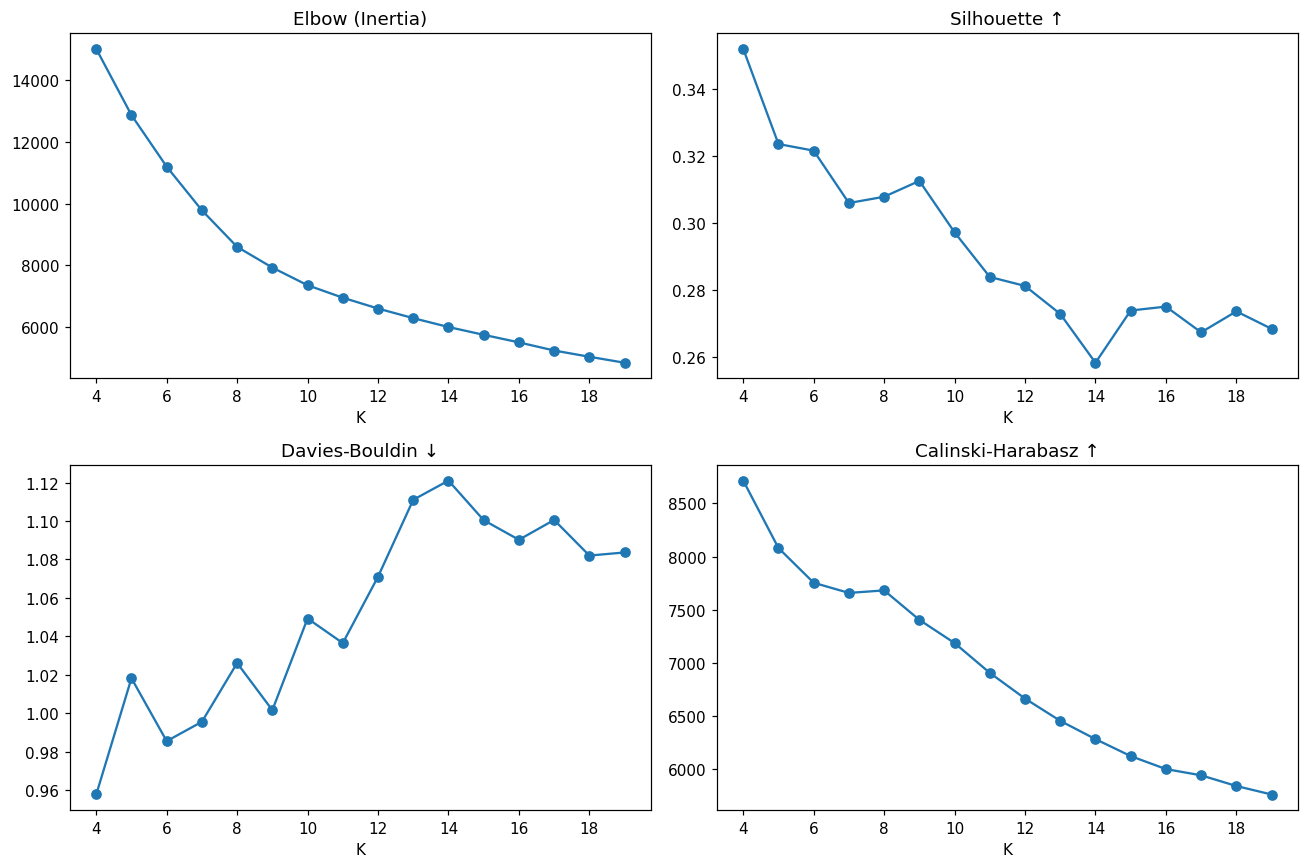

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

def main():
    X = np.load("embeddings/umap_10d.npy")
    Ks = range(4, 20)
    inertia, sil, db, ch = [], [], [], []

    for k in Ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=42)
        lbl = km.fit_predict(X)
        inertia.append(km.inertia_)
        sil.append(silhouette_score(X, lbl))
        db.append(davies_bouldin_score(X, lbl))
        ch.append(calinski_harabasz_score(X, lbl))
        print(f"K={k:2d}  sil={sil[-1]:.4f}  DB={db[-1]:.4f}  CH={ch[-1]:.1f}")

    # Plot
    fig, ax = plt.subplots(2, 2, figsize=(12, 8))
    ax[0,0].plot(Ks, inertia, "o-"); ax[0,0].set_title("Elbow (Inertia)")
    ax[0,1].plot(Ks, sil, "o-");     ax[0,1].set_title("Silhouette ↑")
    ax[1,0].plot(Ks, db, "o-");      ax[1,0].set_title("Davies-Bouldin ↓")
    ax[1,1].plot(Ks, ch, "o-");      ax[1,1].set_title("Calinski-Harabasz ↑")
    for a in ax.ravel(): a.set_xlabel("K")
    plt.tight_layout()
    plt.savefig("figures/k_selection.png", dpi=300)

    best_k = list(Ks)[int(np.argmax(sil))]
    print(f"\n🎯 best_k = {best_k}")
    with open("outputs/best_k.txt", "w") as f:
        f.write(str(best_k))

if __name__ == "__main__":
    main()

In [ ]:
best_k = 4

In [ ]:
import numpy as np, pandas as pd, pickle
from sklearn.cluster import KMeans

def main():
    X = np.load("embeddings/umap_10d.npy")
    best_k = int(open("outputs/best_k.txt").read().strip())

    km = KMeans(n_clusters=best_k, n_init=20, random_state=42)
    labels = km.fit_predict(X)

    df = pd.read_csv("data/processed/cleaned_depression.csv")
    df["cluster"] = labels
    df.to_csv("outputs/clusters.csv", index=False)

    with open("models/kmeans_model.pkl", "wb") as f:
        pickle.dump(km, f)

    print(f"✅ Clustered {len(df)} sentences into {best_k} clusters")
    print(df["cluster"].value_counts().sort_index())

if __name__ == "__main__":
    main()

✅ Clustered 10957 sentences into 4 clusters
cluster
0    2149
1    3052
2    2485
3    3271
Name: count, dtype: int64


In [ ]:
import re, pickle
import numpy as np, pandas as pd
import networkx as nx
import community.community_louvain as community_louvain     # python-louvain
from collections import Counter

# Bangla stopwords (extend as needed)
STOPWORDS = set("""
আমি আমার আমরা আমাদের তুমি তোমার আপনি আপনার সে তার তারা তাদের এই সেই
করে করেছি করছি করব হয় হয়ে হয়েছে ছিল ছিলাম ছিলেন না নেই এবং কিন্তু
তারপর তাই যে যা যার যাকে থেকে জন্য সাথে ও এর কে তো যদি তবে
এক একটা অনেক কিছু কোনো সব আর বা মাঝে মধ্যে কাছে দিকে র
""".split())

WINDOW = 5
MIN_EDGE_WEIGHT = 2
MIN_COMMUNITY = 8
TOP_K_EDGES = 10

def tokenize(t):
    toks = re.findall(r"[\u0980-\u09FF]+", t)
    return [w for w in toks if w not in STOPWORDS and len(w) > 2]

def build_cooc(sentences):
    G = nx.Graph()
    for s in sentences:
        toks = tokenize(s)
        for i, w in enumerate(toks):
            for j in range(i+1, min(i+WINDOW, len(toks))):
                u, v = toks[i], toks[j]
                if u == v: continue
                if G.has_edge(u, v):
                    G[u][v]["weight"] += 1
                else:
                    G.add_edge(u, v, weight=1)
    # prune
    G.remove_edges_from([(u,v) for u,v,d in G.edges(data=True)
                         if d["weight"] < MIN_EDGE_WEIGHT])
    G.remove_nodes_from(list(nx.isolates(G)))
    # top-K edges per node
    H = nx.Graph()
    for n in G.nodes:
        edges = sorted(G[n].items(), key=lambda x: -x[1]["weight"])[:TOP_K_EDGES]
        for v, d in edges:
            H.add_edge(n, v, weight=d["weight"])
    return H

def extract_themes(G):
    if len(G) < 3: return []
    partition = community_louvain.best_partition(G, resolution=1.0, random_state=42)
    mod = community_louvain.modularity(partition, G)

    communities = {}
    for node, cid in partition.items():
        communities.setdefault(cid, []).append(node)

    themes = []
    for cid, nodes in communities.items():
        if len(nodes) < MIN_COMMUNITY: continue
        sub = G.subgraph(nodes)
        deg = dict(sub.degree(weight="weight"))
        top = sorted(deg.items(), key=lambda x: -x[1])[:10]
        themes.append({
            "community_id": cid,
            "keywords": [w for w, _ in top],
            "size": len(nodes),
            "modularity": mod,
        })
    return themes

def assign_theme_to_sentences(sentences, G, themes, cluster_id):
    # build word -> theme map
    partition = community_louvain.best_partition(G, resolution=1.0, random_state=42)
    w2t = partition
    theme_ids = {t["community_id"]: i for i, t in enumerate(themes)}

    rows = []
    for s in sentences:
        toks = tokenize(s)
        votes = Counter()
        for w in toks:
            if w in w2t and w2t[w] in theme_ids:
                votes[theme_ids[w2t[w]]] += 1
        theme = votes.most_common(1)[0][0] if votes else -1
        rows.append({"text": s, "cluster": cluster_id, "theme_id": theme})
    return rows

def main():
    df = pd.read_csv("outputs/clusters.csv")
    all_theme_rows, theme_info_rows = [], []
    graphs = {}

    for cid in sorted(df["cluster"].unique()):
        sents = df[df["cluster" ] == cid]["text"].tolist()
        print(f"\n🔹 Cluster {cid}  (n={len(sents)})")

        G = build_cooc(sents)
        graphs[cid] = G
        themes = extract_themes(G)

        print(f"  → {len(themes)} themes found")
        for i, t in enumerate(themes):
            print(f"     theme {i}: {t['keywords'][:5]}  (size={t['size']})")
            theme_info_rows.append({
                "cluster": cid, "theme_id": i,
                "keywords": ", ".join(t["keywords"]),
                "size": t["size"],
            })

        all_theme_rows.extend(assign_theme_to_sentences(sents, G, themes, cid))

    pd.DataFrame(theme_info_rows).to_csv("outputs/cluster_themes.csv", index=False)
    pd.DataFrame(all_theme_rows).to_csv("outputs/themes_final.csv", index=False)
    with open("models/cooccurrence_graphs.pkl", "wb") as f:
        pickle.dump(graphs, f)

    print("\n✅ Saved themes_final.csv & cluster_themes.csv")

if __name__ == "__main__":
    main()


🔹 Cluster 0  (n=2149)
  → 17 themes found
     theme 0: ['সত্যিই', 'খারাপ', 'বোধ', 'অনুভব', 'ভাল']  (size=722)
     theme 1: ['চাই', 'মরতে', 'থাকতে', 'বাঁচতে', 'বন্ধ']  (size=527)
     theme 2: ['জানি', 'কিভাবে', 'কিনা', 'কীভাবে', 'মানুষ']  (size=197)
     theme 3: ['নিজেকে', 'ঘৃণা', 'হত্যা', 'মেরে', 'আঘাত']  (size=241)
     theme 4: ['জীবন', 'থাকার', 'বেঁচে', 'যোগ্য', 'সারা']  (size=165)
     theme 5: ['কথা', 'সম্পর্কে', 'চিন্তা', 'আত্মহত্যার', 'বলার']  (size=347)
     theme 6: ['সাহায্য', 'করুন', 'দয়া', 'বুঝতে', 'ধন্যবাদ']  (size=256)
     theme 7: ['শেষ', 'আছি', 'আশা', 'ভালো', 'এমনকি']  (size=288)
     theme 8: ['মারা', 'হারিয়ে', 'যাই', 'ধীরে', 'ফেলেছি']  (size=123)
     theme 9: ['কারণে', 'মানসিক', 'পেতে', 'চাকরি', 'সিদ্ধান্ত']  (size=207)
     theme 10: ['বন্ধু', 'পরিবার', 'যত্ন', 'বন্ধুরা', 'তৈরি']  (size=103)
     theme 11: ['ক্লান্ত', 'জেগে', 'পড়েছি', 'উঠতে', 'ঘুমিয়ে']  (size=129)
     theme 12: ['ভয়', 'খুঁজে', 'পাচ্ছি', 'পাই', 'বের']  (size=137)
     theme 13: ['যাচ্ছি',

In [ ]:
import re, pickle
import numpy as np, pandas as pd
import networkx as nx
import community.community_louvain as community_louvain     # python-louvain
from collections import Counter

# Bangla stopwords (extend as needed)
STOPWORDS = set("""
আমি আমার আমরা আমাদের তুমি তোমার আপনি আপনার সে তার তারা তাদের এই সেই
করে করেছি করছি করব হয় হয়ে হয়েছে ছিল ছিলাম ছিলেন না নেই এবং কিন্তু
তারপর তাই যে যা যার যাকে থেকে জন্য সাথে ও এর কে তো যদি তবে
এক একটা অনেক কিছু কোনো সব আর বা মাঝে মধ্যে কাছে দিকে র
""".split())

WINDOW = 5
MIN_EDGE_WEIGHT = 2
MIN_COMMUNITY = 8
TOP_K_EDGES = 10

def tokenize(t):
    toks = re.findall(r"[\u0980-\u09FF]+", t)
    return [w for w in toks if w not in STOPWORDS and len(w) > 2]

def build_cooc(sentences):
    G = nx.Graph()
    for s in sentences:
        toks = tokenize(s)
        for i, w in enumerate(toks):
            for j in range(i+1, min(i+WINDOW, len(toks))):
                u, v = toks[i], toks[j]
                if u == v: continue
                if G.has_edge(u, v):
                    G[u][v]["weight"] += 1
                else:
                    G.add_edge(u, v, weight=1)
    # prune
    G.remove_edges_from([(u,v) for u,v,d in G.edges(data=True)
                         if d["weight"] < MIN_EDGE_WEIGHT])
    G.remove_nodes_from(list(nx.isolates(G)))
    # top-K edges per node
    H = nx.Graph()
    for n in G.nodes:
        edges = sorted(G[n].items(), key=lambda x: -x[1]["weight"])[:TOP_K_EDGES]
        for v, d in edges:
            H.add_edge(n, v, weight=d["weight"])
    return H

def extract_themes(G):
    if len(G) < 3: return []
    partition = community_louvain.best_partition(G, resolution=1.0, random_state=42)
    mod = community_louvain.modularity(partition, G)

    communities = {}
    for node, cid in partition.items():
        communities.setdefault(cid, []).append(node)

    themes = []
    for cid, nodes in communities.items():
        if len(nodes) < MIN_COMMUNITY: continue
        sub = G.subgraph(nodes)
        deg = dict(sub.degree(weight="weight"))
        top = sorted(deg.items(), key=lambda x: -x[1])
        themes.append({
            "community_id": cid,
            "keywords": [w for w, _ in top],
            "size": len(nodes),
            "modularity": mod,
        })
    return themes

def assign_theme_to_sentences(sentences, G, themes, cluster_id):
    # build word -> theme map
    partition = community_louvain.best_partition(G, resolution=1.0, random_state=42)
    w2t = partition
    theme_ids = {t["community_id"]: i for i, t in enumerate(themes)}

    rows = []
    for s in sentences:
        toks = tokenize(s)
        votes = Counter()
        for w in toks:
            if w in w2t and w2t[w] in theme_ids:
                votes[theme_ids[w2t[w]]] += 1
        theme = votes.most_common(1)[0][0] if votes else -1
        rows.append({"text": s, "cluster": cluster_id, "theme_id": theme})
    return rows

def main():
    df = pd.read_csv("outputs/clusters.csv")
    all_theme_rows, theme_info_rows = [], []
    graphs = {}

    for cid in sorted(df["cluster"].unique()):
        sents = df[df["cluster"] == cid]["text"].tolist()
        print(f"\n🔹 Cluster {cid}  (n={len(sents)})")

        G = build_cooc(sents)
        graphs[cid] = G
        themes = extract_themes(G)

        print(f"  → {len(themes)} themes found")
        for i, t in enumerate(themes):
            print(f"     theme {i}: {t['keywords'][:5]}  (size={t['size']})")
            theme_info_rows.append({
                "cluster": cid, "theme_id": i,
                "keywords": ", ".join(t["keywords"]),
                "size": t["size"],
            })

        all_theme_rows.extend(assign_theme_to_sentences(sents, G, themes, cid))

    pd.DataFrame(theme_info_rows).to_csv("outputs/cluster_themes12.csv", index=False)
    # pd.DataFrame(all_theme_rows).to_csv("outputs/themes_final.csv", index=False)
    with open("models/cooccurrence_graphs.pkl", "wb") as f:
        pickle.dump(graphs, f)

    print("\n✅ Saved themes_final.csv & cluster_themes.csv")

if __name__ == "__main__":
    main()


🔹 Cluster 0  (n=2149)
  → 17 themes found
     theme 0: ['সত্যিই', 'খারাপ', 'বোধ', 'অনুভব', 'ভাল']  (size=722)
     theme 1: ['চাই', 'মরতে', 'থাকতে', 'বাঁচতে', 'বন্ধ']  (size=527)
     theme 2: ['জানি', 'কিভাবে', 'কিনা', 'কীভাবে', 'মানুষ']  (size=197)
     theme 3: ['নিজেকে', 'ঘৃণা', 'হত্যা', 'মেরে', 'আঘাত']  (size=241)
     theme 4: ['জীবন', 'থাকার', 'বেঁচে', 'যোগ্য', 'সারা']  (size=165)
     theme 5: ['কথা', 'সম্পর্কে', 'চিন্তা', 'আত্মহত্যার', 'বলার']  (size=347)
     theme 6: ['সাহায্য', 'করুন', 'দয়া', 'বুঝতে', 'ধন্যবাদ']  (size=256)
     theme 7: ['শেষ', 'আছি', 'আশা', 'ভালো', 'এমনকি']  (size=288)
     theme 8: ['মারা', 'হারিয়ে', 'যাই', 'ধীরে', 'ফেলেছি']  (size=123)
     theme 9: ['কারণে', 'মানসিক', 'পেতে', 'চাকরি', 'সিদ্ধান্ত']  (size=207)
     theme 10: ['বন্ধু', 'পরিবার', 'যত্ন', 'বন্ধুরা', 'তৈরি']  (size=103)
     theme 11: ['ক্লান্ত', 'জেগে', 'পড়েছি', 'উঠতে', 'ঘুমিয়ে']  (size=129)
     theme 12: ['ভয়', 'খুঁজে', 'পাচ্ছি', 'পাই', 'বের']  (size=137)
     theme 13: ['যাচ্ছি',

In [ ]:
!pip install -q bangla-render==0.2.1
!apt-get install -y fonts-noto-core

import glob, os, matplotlib
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt

# Noto Sans Bengali font path বের করা
font_files = glob.glob('/usr/share/fonts/**/NotoSansBengali-Regular.ttf', recursive=True)
if not font_files:
    raise FileNotFoundError("NotoSansBengali-Regular.ttf not found!")
font_path = font_files[0]
print("Font found:", font_path)

# Matplotlib font cache clear + font register
cache_dir = matplotlib.get_cachedir()
for f in glob.glob(os.path.join(cache_dir, 'fontlist-v*.json')):
    os.remove(f)
fm.fontManager.addfont(font_path)

# Font family name বের করা (register করার পরে)
font_name = fm.FontProperties(fname=font_path).get_name()
print("Registered font family:", font_name)

# Global rcParams-এ set করা (NetworkX labels-এর জন্য critical)
plt.rcParams['font.family'] = font_name
plt.rcParams['axes.unicode_minus'] = False

# bangla_render initialize (title/axis labels-এর জন্য)
import bangla_render as br
br.init_renderer()

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-noto-core is already the newest version (20201225-2).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.
Font found: /usr/share/fonts/truetype/noto/NotoSansBengali-Regular.ttf
Registered font family: Noto Sans Bengali


<PySide6.QtWidgets.QApplication(0x5e7b31c0) at 0x788d31f365c0>

✅ Saved → figures/cooccurrence/cluster_0_graph.png


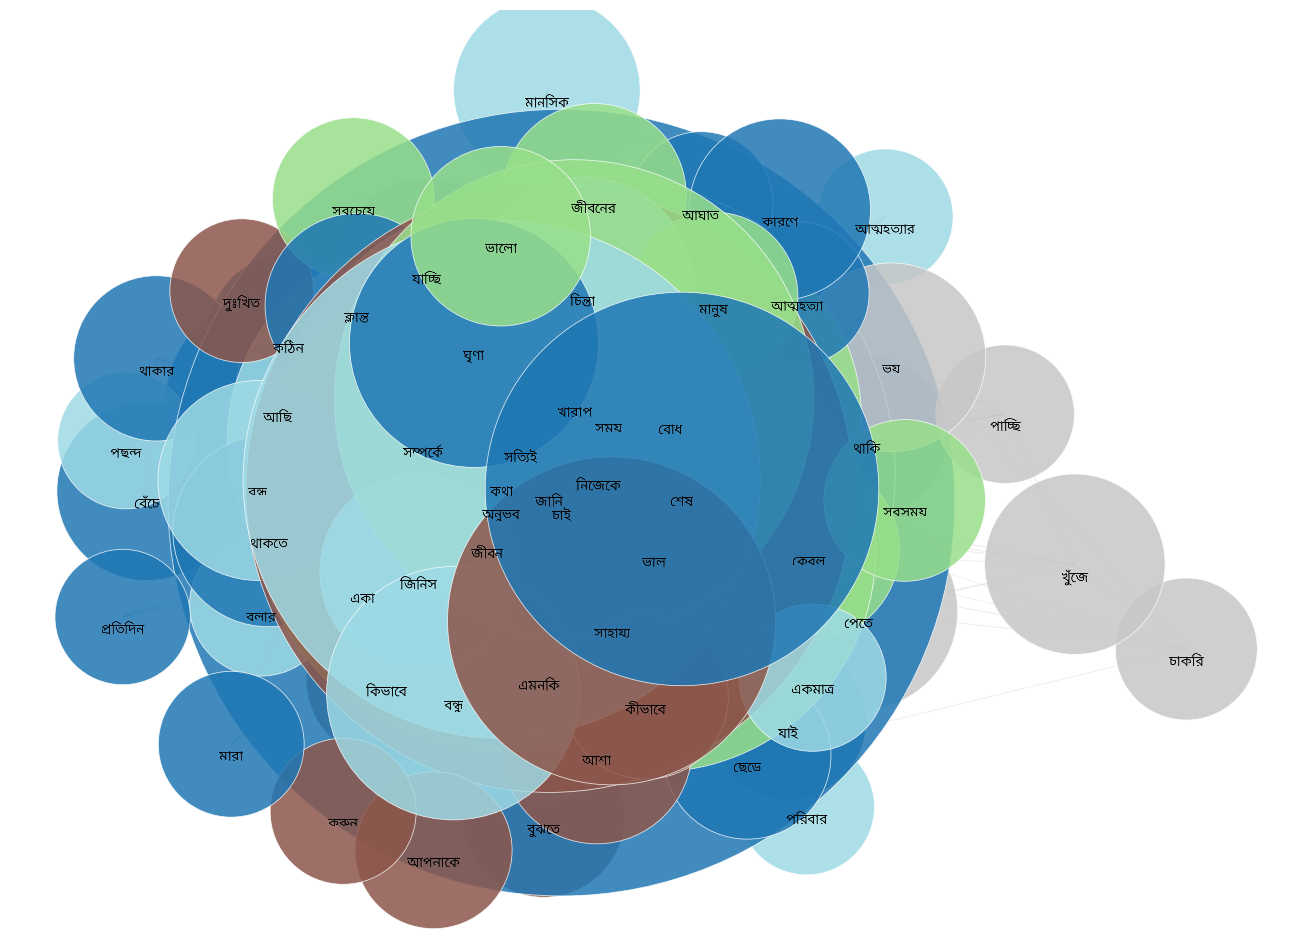

✅ Saved → figures/cooccurrence/cluster_1_graph.png


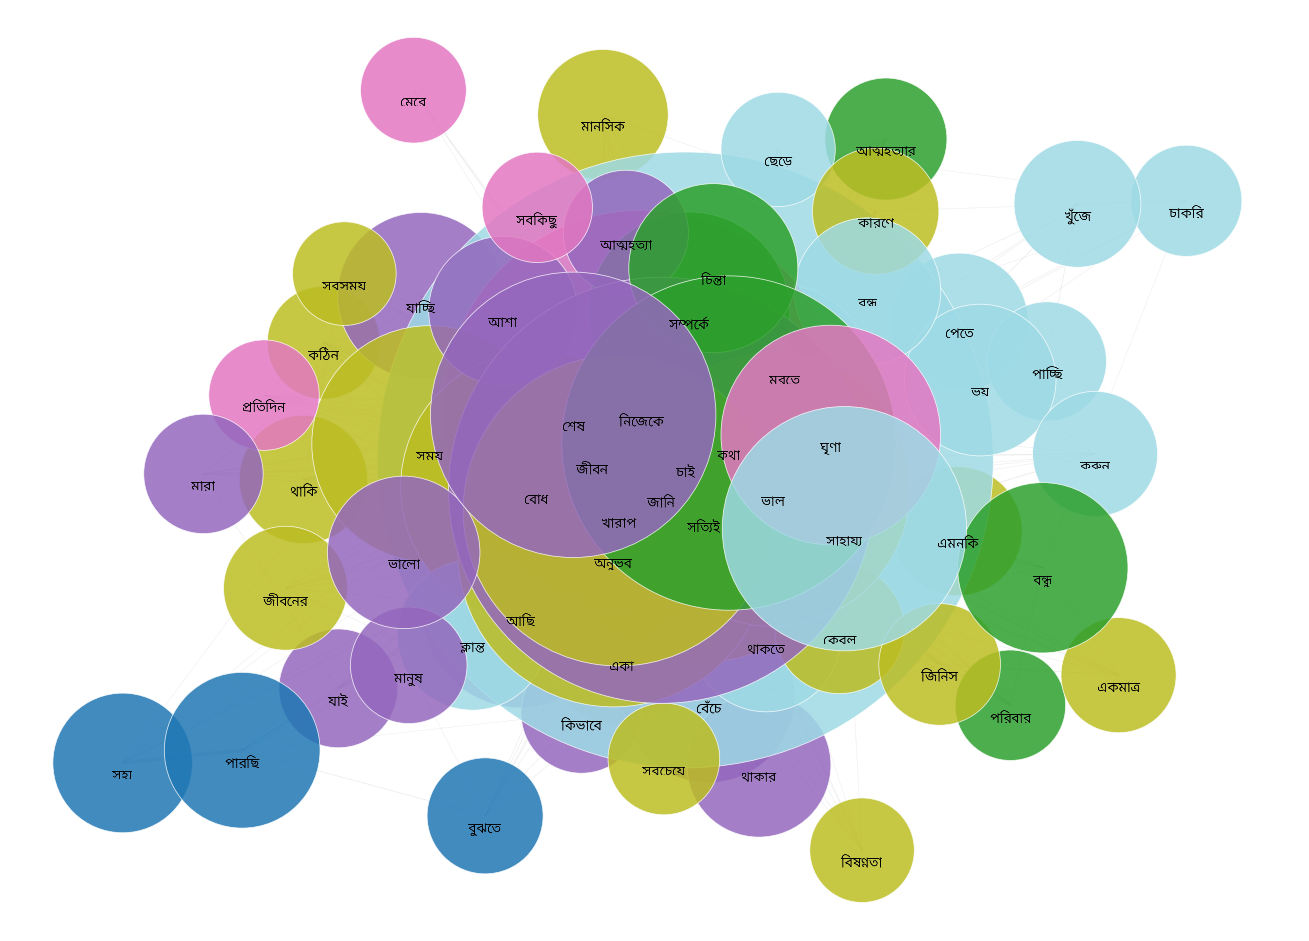

In [ ]:
import pickle, os
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from PIL import Image, ImageDraw, ImageFont
import io

# --- Load the graphs dictionary from pickle (Fixes NameError) ---
with open("models/cooccurrence_graphs.pkl", "rb") as f:
    graphs = pickle.load(f)

# --- Font setup (আপনার আগের setup-এর পরে) ---
# font_path, font_name globally available ধরে নিচ্ছি
# font_path = '/usr/share/fonts/.../NotoSansBengali-Regular.ttf'

# ---------- Helper: বাংলা text → transparent PNG ----------
def bangla_text_to_image(text, font_path, fontsize=30, pad=4, dpi=200):
    """
    bangla_render-এর শেপিং ব্যবহার করে বাংলা text-কে PNG বানায়।
    (matplotlib-এর bug bypass করে।)
    """
    import bangla_render as br

    # bangla_render-এর internal shaper ব্যবহার করা
    try:
        # নতুন version-এ এই API থাকতে পারে
        shaped = br.shape_text(text, font_path=font_path)
    except AttributeError:
        # fallback: bangla_render-এর matplotlib-text path বানানোর helper
        shaped = None

    # Pillow দিয়ে render — Pillow libraqm থাকলে shaping কাজ করে
    # Colab-এর Pillow সাধারণত libraqm সহ আসে
    font = ImageFont.truetype(font_path, fontsize)

    # text size বের করা
    dummy = Image.new("RGBA", (1, 1))
    d = ImageDraw.Draw(dummy)
    bbox = d.textbbox((0, 0), text, font=font)
    w = bbox[2] - bbox[0] + pad * 2
    h = bbox[3] - bbox[1] + pad * 2

    img = Image.new("RGBA", (w, h), (255, 255, 255, 0))
    d = ImageDraw.Draw(img)
    d.text((pad, pad), text, font=font, fill=(0, 0, 0, 255))
    return np.array(img)


# ---------- Main plot ----------
def plot_cluster_graph(G, cluster_id, top_n=80, save_path=None):
    if len(G) == 0:
        print(f"Cluster {cluster_id}: empty graph")
        return

    deg = dict(G.degree(weight="weight"))
    top_nodes = [n for n, _ in sorted(deg.items(), key=lambda x: -x[1])[:top_n]]
    H = G.subgraph(top_nodes).copy()

    pos = nx.spring_layout(H, k=0.6, iterations=50, seed=42, weight="weight")

    node_sizes = [deg[n] * 5 + 50 for n in H.nodes()]
    edge_weights = [H[u][v]["weight"] for u, v in H.edges()]
    max_w = max(edge_weights) if edge_weights else 1
    edge_widths = [0.3 + 2.5 * (w / max_w) for w in edge_weights]

    try:
        import community.community_louvain as community_louvain
        partition = community_louvain.best_partition(H, weight="weight", random_state=42)
        colors = [partition[n] for n in H.nodes()]
    except Exception:
        colors = [0] * len(H.nodes())

    fig, ax = plt.subplots(figsize=(15, 11))

    # edges
    nx.draw_networkx_edges(H, pos, width=edge_widths, alpha=0.15,
                           edge_color="gray", ax=ax)

    # nodes
    nx.draw_networkx_nodes(H, pos, node_size=node_sizes,
                           node_color=colors, cmap="tab20",
                           alpha=0.85, edgecolors="white",
                           linewidths=0.5, ax=ax)

    # ⭐⭐ CRITICAL: প্রতিটি label আলাদা image হিসেবে বসানো
    for n in H.nodes():
        img = bangla_text_to_image(n, font_path, fontsize=25, dpi=200)
        im = OffsetImage(img, zoom=0.35)   # zoom adjust করে size কমানো-বাড়ানো
        x, y = pos[n]
        ab = AnnotationBbox(im, (x, y),
                            frameon=False,
                            box_alignment=(0.5, 1.15),  # node-এর উপরে
                            pad=0.0)
        ax.add_artist(ab)

    # br.set_bangla_title(
    #     ax,
    #     f"Cluster {cluster_id} — Co-occurrence Graph "
    #     f"(nodes={H.number_of_nodes()}, edges={H.number_of_edges()})",
    #     font_path=font_path,
    #     fontsize=25
    # )

    ax.axis("off")
    plt.tight_layout()
    br.apply_bangla_layout(fig, auto=True)

    if save_path:
        plt.savefig(save_path, dpi=250, bbox_inches="tight")
        print(f"✅ Saved → {save_path}")
    plt.show()
    plt.close()


os.makedirs("figures/cooccurrence", exist_ok=True)
for cid in sorted(graphs.keys()):
    plot_cluster_graph(
        graphs[cid], cid, top_n=60,
        save_path=f"figures/cooccurrence/cluster_{cid}_graph.png"
    )

✅ Saved → figures/cooccurrence/cluster_0_graph.png


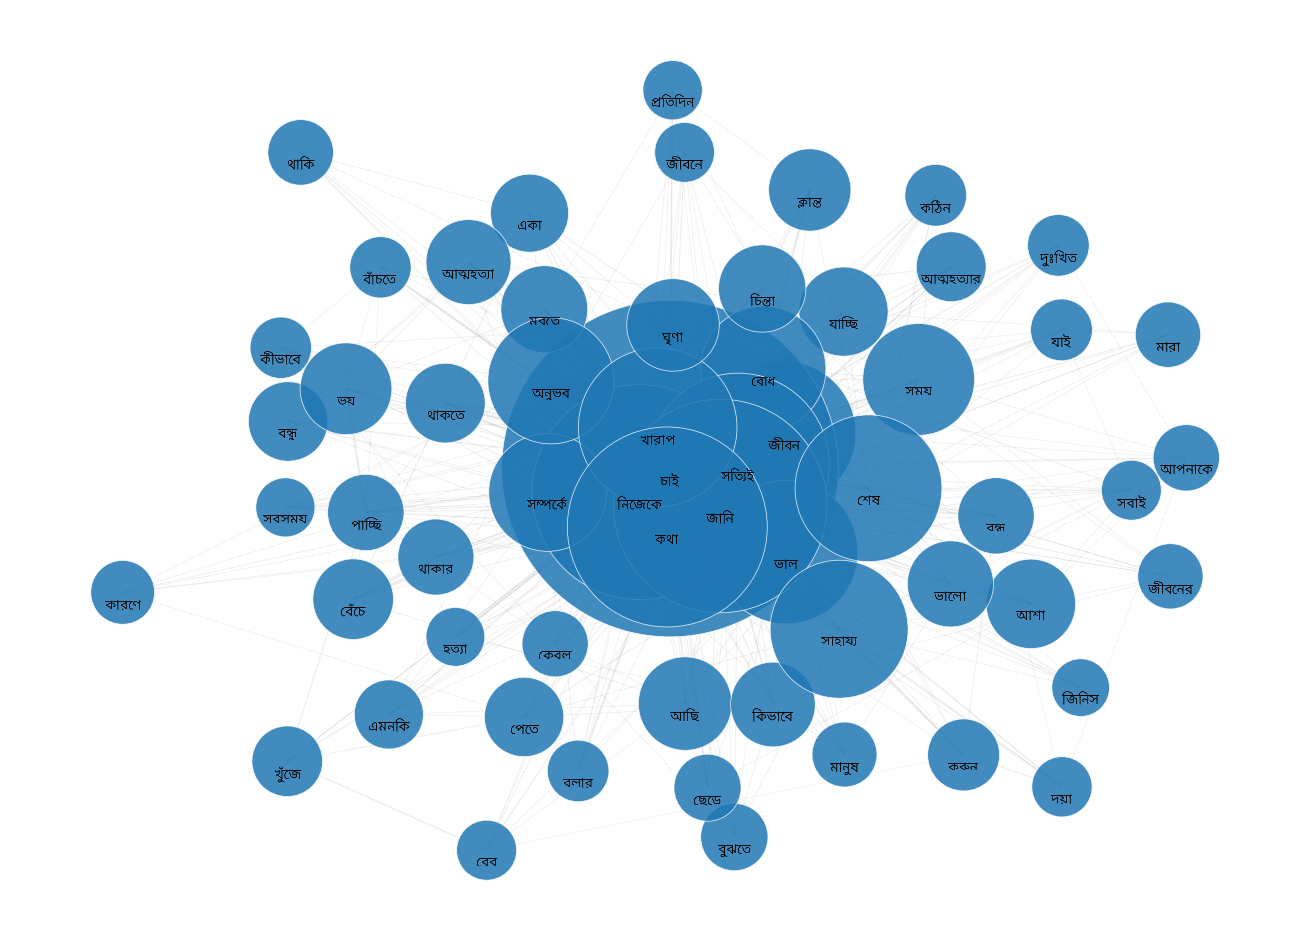

✅ Saved → figures/cooccurrence/cluster_1_graph.png


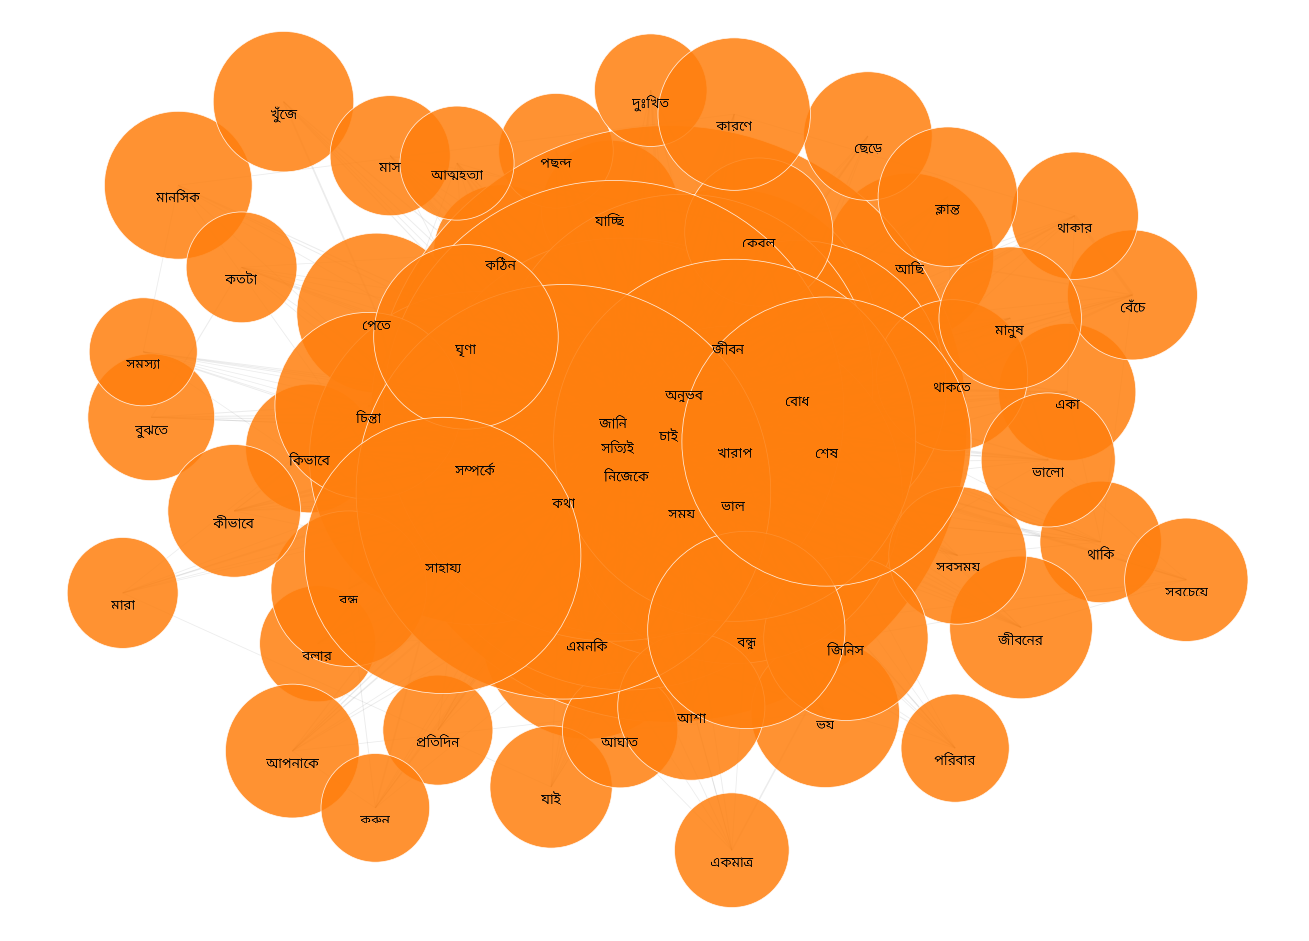

✅ Saved → figures/cooccurrence/cluster_2_graph.png


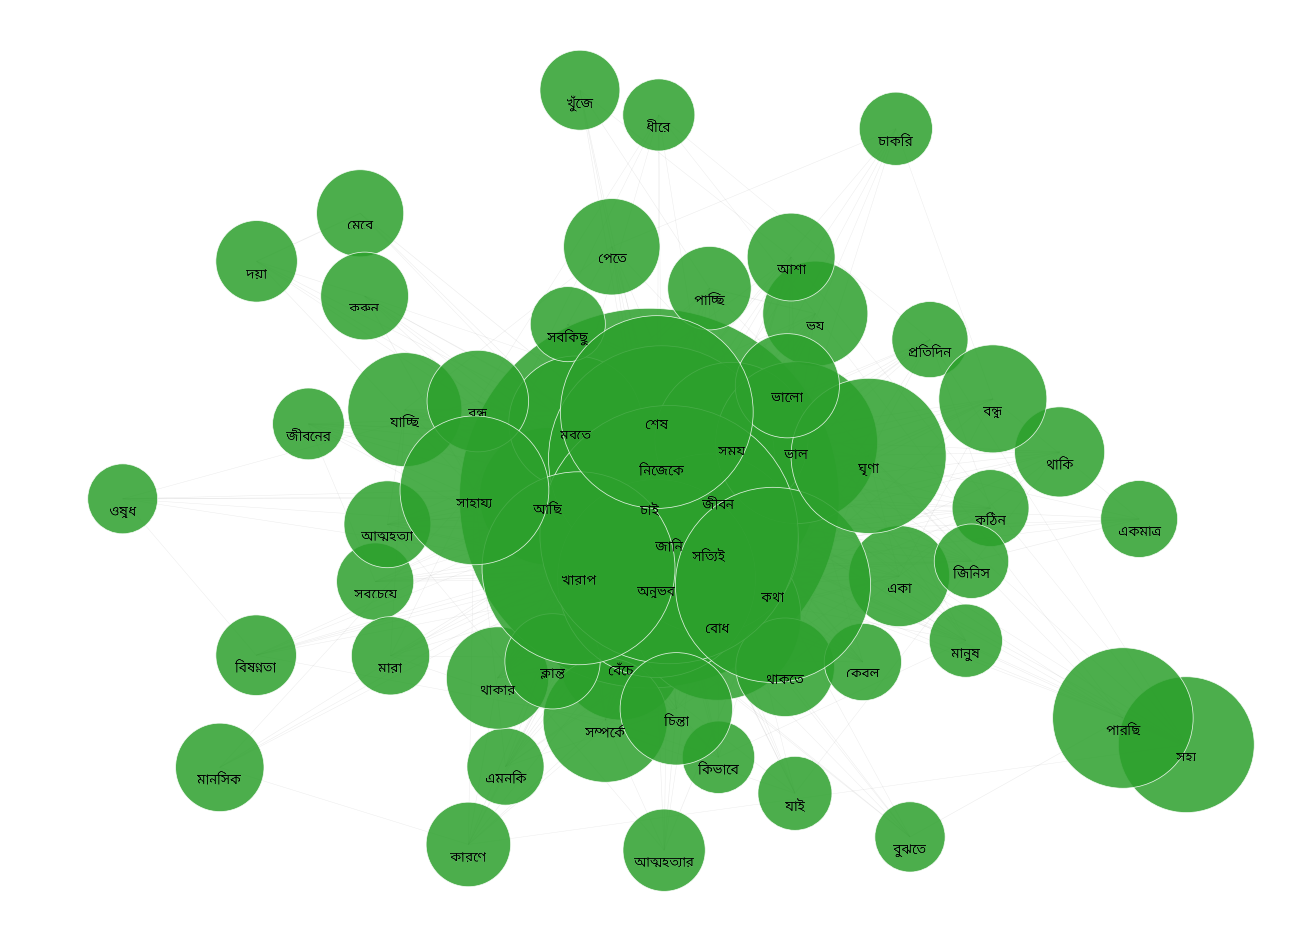

✅ Saved → figures/cooccurrence/cluster_3_graph.png


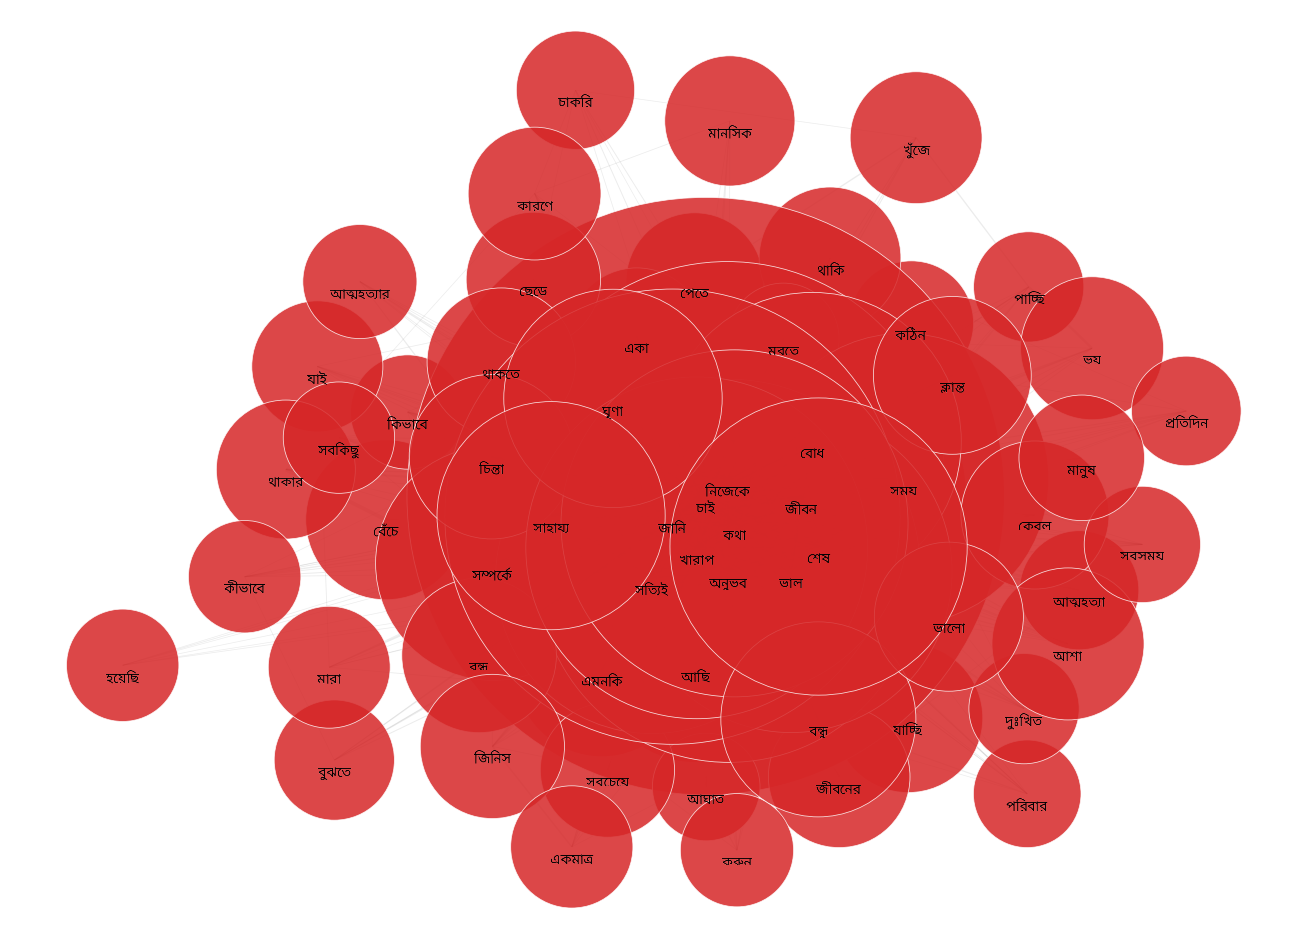

In [ ]:
import pickle, os
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from PIL import Image, ImageDraw, ImageFont
import io

# --- Load the graphs dictionary from pickle (Fixes NameError) ---
with open("models/cooccurrence_graphs.pkl", "rb") as f:
    graphs = pickle.load(f)

# --- Custom Vibrant Theme Color Palette for each Cluster ---
cluster_theme_colors = {
    0: "#1f77b4",  # Deep Blue
    1: "#ff7f0e",  # Warm Orange
    2: "#2ca02c",  # Forest Green
    3: "#d62728",  # Crimson Red
    4: "#9467bd"   # Velvet Purple
}

# ---------- Helper: বাংলা text → transparent PNG ----------
def bangla_text_to_image(text, font_path, fontsize=30, pad=4, dpi=200):
    """
    bangla_render-এর শেপিং ব্যবহার করে বাংলা text-কে PNG বানায়।
    (matplotlib-এর bug bypass করে।)
    """
    import bangla_render as br

    # bangla_render-এর internal shaper ব্যবহার করা
    try:
        shaped = br.shape_text(text, font_path=font_path)
    except AttributeError:
        shaped = None

    font = ImageFont.truetype(font_path, fontsize)

    # text size বের করা
    dummy = Image.new("RGBA", (1, 1))
    d = ImageDraw.Draw(dummy)
    bbox = d.textbbox((0, 0), text, font=font)
    w = bbox[2] - bbox[0] + pad * 2
    h = bbox[3] - bbox[1] + pad * 2

    img = Image.new("RGBA", (w, h), (255, 255, 255, 0))
    d = ImageDraw.Draw(img)
    d.text((pad, pad), text, font=font, fill=(1, 2, 3, 255))
    return np.array(img)


# ---------- Main plot ----------
def plot_cluster_graph(G, cluster_id, top_n=60, save_path=None):
    if len(G) == 0:
        print(f"Cluster {cluster_id}: empty graph")
        return

    deg = dict(G.degree(weight="weight"))
    top_nodes = [n for n, _ in sorted(deg.items(), key=lambda x: -x[1])[:top_n]]
    H = G.subgraph(top_nodes).copy()

    pos = nx.spring_layout(H, k=0.6, iterations=50, seed=42, weight="weight")

    node_sizes = [deg[n] * 5 + 50 for n in H.nodes()]
    edge_weights = [H[u][v]["weight"] for u, v in H.edges()]
    max_w = max(edge_weights) if edge_weights else 1
    edge_widths = [0.3 + 2.5 * (w / max_w) for w in edge_weights]

    # Determine background color based on cluster id mapping
    node_color_choice = cluster_theme_colors.get(cluster_id, "#34495e")

    fig, ax = plt.subplots(figsize=(15, 11))

    # edges
    nx.draw_networkx_edges(H, pos, width=edge_widths, alpha=0.15,
                           edge_color="gray", ax=ax)

    # nodes with custom color
    nx.draw_networkx_nodes(H, pos, node_size=node_sizes,
                           node_color=node_color_choice,
                           alpha=0.85, edgecolors="white",
                           linewidths=0.5, ax=ax)

    # label placement
    for n in H.nodes():
        img = bangla_text_to_image(n, font_path, fontsize=25, dpi=200)
        im = OffsetImage(img, zoom=0.35)
        x, y = pos[n]
        ab = AnnotationBbox(im, (x, y),
                            frameon=False,
                            box_alignment=(0.5, 1.15),
                            pad=0.0)
        ax.add_artist(ab)

    ax.axis("off")
    plt.tight_layout()
    br.apply_bangla_layout(fig, auto=True)

    if save_path:
        plt.savefig(save_path, dpi=250, bbox_inches="tight")
        print(f"✅ Saved → {save_path}")
    plt.show()
    plt.close()


os.makedirs("figures/cooccurrence", exist_ok=True)
for cid in sorted(graphs.keys()):
    plot_cluster_graph(
        graphs[cid], cid, top_n=60,
        save_path=f"figures/cooccurrence/cluster_{cid}_graph.png"
    )

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# Load data and define cluster_ids
X  = np.load("embeddings/umap_10d.npy")
df = pd.read_csv("outputs/clusters.csv")
cluster_ids = sorted(df["cluster"].unique())

rows = []
for c in cluster_ids:
    idx = np.where(df["cluster"].values == c)[0]
    Xc = X[idx]
    center = Xc.mean(axis=0, keepdims=True)
    # centroid-এর সাথে প্রতিটি point-এর similarity
    sims_to_center = cosine_similarity(Xc, center).ravel()

    # pair-wise average similarity (subsample for speed)
    n = len(Xc)
    if n > 800:
        sample = np.random.RandomState(42).choice(n, 800, replace=False)
        Xs = Xc[sample]
    else:
        Xs = Xc
    pairwise = cosine_similarity(Xs)
    # upper triangle only (self-sim বাদ দিয়ে)
    iu = np.triu_indices_from(pairwise, k=1)
    avg_pair_sim = pairwise[iu].mean()

    rows.append({
        "cluster": c,
        "size": n,
        "mean_sim_to_centroid": round(sims_to_center.mean(), 4),
        "min_sim_to_centroid": round(sims_to_center.min(), 4),
        "std_sim_to_centroid": round(sims_to_center.std(), 4),
        "avg_pairwise_similarity": round(avg_pair_sim, 4),
        "low_conf(<0.5)": int((sims_to_center < 0.5).sum()),
    })

coherence = pd.DataFrame(rows)
coherence.to_csv("outputs/cluster_coherence.csv", index=False)
print("\nIntra-Cluster Coherence:")
print(coherence.to_string(index=False))


Intra-Cluster Coherence:
 cluster  size  mean_sim_to_centroid  min_sim_to_centroid  std_sim_to_centroid  avg_pairwise_similarity  low_conf(<0.5)
       0  2149                0.9977               0.9909               0.0016                   0.9954               0
       1  3052                0.9975               0.9898               0.0014                   0.9950               0
       2  2485                0.9980               0.9939               0.0011                   0.9961               0
       3  3271                0.9976               0.9931               0.0013                   0.9952               0


In [ ]:
import ast
from itertools import combinations

themes = pd.read_csv("outputs/cluster_themes.csv")

# per-cluster keyword set
kw_sets = {}
for c in cluster_ids:
    words = set()
    for kws in themes[themes["cluster"] == c]["keywords"]:
        words.update(str(kws).split(", "))
    kw_sets[c] = words

print("\nTheme Keyword Overlap (Jaccard):")
jaccard = pd.DataFrame(index=[f"C{c}" for c in cluster_ids],
                       columns=[f"C{c}" for c in cluster_ids],
                       dtype=float)

for a in cluster_ids:
    for b in cluster_ids:
        A, B = kw_sets[a], kw_sets[b]
        if not A and not B:
            jaccard.loc[f"C{a}", f"C{b}"] = 0.0
            continue
        j = len(A & B) / len(A | B)
        jaccard.loc[f"C{a}", f"C{b}"] = round(j, 3)

print(jaccard.to_string())

# Top shared keywords list
print("\nTop shared keywords between cluster pairs:")
for a, b in combinations(cluster_ids, 2):
    shared = kw_sets[a] & kw_sets[b]
    if shared:
        print(f"  C{a} ↔ C{b}: {sorted(shared)[:12]}")


Theme Keyword Overlap (Jaccard):
       C0     C1     C2     C3
C0  1.000  0.350  0.326  0.471
C1  0.350  1.000  0.336  0.481
C2  0.326  0.336  1.000  0.457
C3  0.471  0.481  0.457  1.000

Top shared keywords between cluster pairs:
  C0 ↔ C1: ['অনুভব', 'অর্থ', 'অর্থে', 'আঘাত', 'আছি', 'আত্মহত্যা', 'আত্মহত্যার', 'আপনাকে', 'আশা', 'উপায়', 'একা', 'এমনকি']
  C0 ↔ C2: ['অনুভব', 'অর্থ', 'অর্থে', 'আঘাত', 'আছি', 'আত্মহত্যা', 'আত্মহত্যার', 'আপনাকে', 'আশা', 'ইচ্ছা', 'উঠতে', 'উঠি']
  C0 ↔ C3: ['অনুভব', 'অর্থ', 'অর্থে', 'আঘাত', 'আছি', 'আত্মহত্যা', 'আত্মহত্যার', 'আপনাকে', 'আশা', 'উঠতে', 'উঠি', 'উপায়']
  C1 ↔ C2: ['অনুভব', 'অনুভূতি', 'অর্থ', 'অর্থে', 'আক্ষরিক', 'আঘাত', 'আছি', 'আটকে', 'আত্মহত্যা', 'আত্মহত্যার', 'আপনাকে', 'আশা']
  C1 ↔ C3: ['অনুভব', 'অনুভূতি', 'অর্থ', 'অর্থে', 'আক্ষরিক', 'আঘাত', 'আছি', 'আটকে', 'আত্মহত্যা', 'আত্মহত্যার', 'আপনাকে', 'আশা']
  C2 ↔ C3: ['অনুভব', 'অনুভূতি', 'অর্থ', 'অর্থে', 'অর্থেই', 'অসুস্থ', 'আক্ষরিক', 'আঘাত', 'আছি', 'আটকে', 'আত্মহত্যা', 'আত্মহত্যার']


/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Bengali.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Bengali.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 67 (C) missing from font(s) Noto Sans Bengali.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 74 (J) missing from font(s) Noto Sans Bengali.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 97 (a) missing from font(s) Noto Sans Bengali.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 99 (c) missing from font(s) Noto Sans Bengali.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 114 (r) missing from font(s) Noto Sa

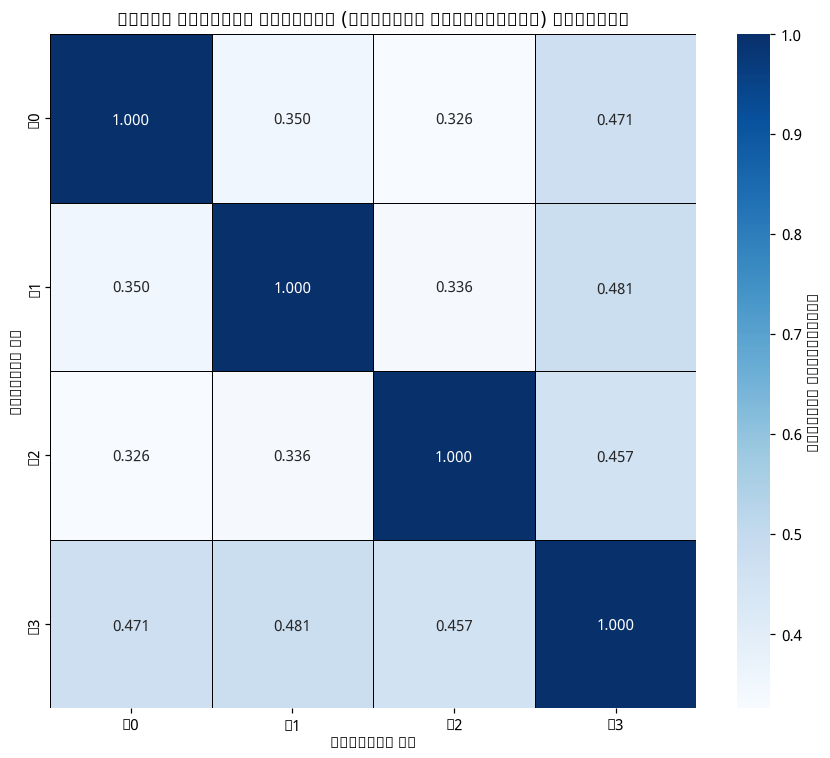

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pandas as pd
import ast
from itertools import combinations

os.makedirs("figures", exist_ok=True)

# Define file paths
clusters_path = "outputs/clusters.csv"
themes_path = "outputs/cluster_themes.csv"

# Flag to determine if all necessary files are found
all_files_found = True

if not os.path.exists(clusters_path):
    print(f"Error: Required file '{clusters_path}' not found.")
    print("Please ensure that cell 'u-gz5rQMAiPS' has been executed successfully to create this file.")
    all_files_found = False

if not os.path.exists(themes_path):
    print(f"Error: Required file '{themes_path}' not found.")
    print("Please ensure that cell 'fwf6B9KKDvTj' has been executed successfully to create this file.")
    all_files_found = False

if all_files_found:
    # Load cluster data to get cluster_ids
    df_clusters = pd.read_csv(clusters_path)
    cluster_ids = sorted(df_clusters["cluster"].unique())

    # Load themes to get keywords
    themes = pd.read_csv(themes_path)

    # per-cluster keyword set
    kw_sets = {}
    for c in cluster_ids:
        words = set()
        for kws in themes[themes["cluster"] == c]["keywords"]:
            words.update(str(kws).split(", "))
        kw_sets[c] = words

    jaccard = pd.DataFrame(index=[f"C{c}" for c in cluster_ids],
                           columns=[f"C{c}" for c in cluster_ids],
                           dtype=float)

    for a in cluster_ids:
        for b in cluster_ids:
            A, B = kw_sets[a], kw_sets[b]
            if not A and not B:
                jaccard.loc[f"C{a}", f"C{b}"] = 0.0
                continue
            union_len = len(A | B)
            if union_len == 0:
                jaccard.loc[f"C{a}", f"C{b}"] = 0.0
            else:
                j = len(A & B) / union_len
                jaccard.loc[f"C{a}", f"C{b}"] = round(j, 3)

    plt.figure(figsize=(8, 7))
    sns.heatmap(
        jaccard,
        annot=True,
        fmt=".3f",
        cmap="Blues",
        linewidths=.5,
        linecolor="black",
        cbar_kws={'label': 'Jaccard Similarity'}
    )
    plt.title('Theme Keyword Overlap (Jaccard Similarity) Heatmap')
    plt.xlabel('Cluster ID')
    plt.ylabel('Cluster ID')
    plt.tight_layout()
    plt.savefig('figures/theme_keyword_overlap_heatmap.png', dpi=300)
    plt.show()
else:
    print("Cannot generate heatmap due to missing input files.")


Cluster Confidence Stats:
           mean  median     std     min     max  count
cluster                                               
0        0.9958  0.9963  0.0026  0.9825  0.9999   5482
1        0.9953  0.9959  0.0030  0.9833  0.9999   5475


/tmp/ipykernel_1713/1621179381.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sim_scores, x="cluster", y="cluster_confidence",
/tmp/ipykernel_1713/1621179381.py:46: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Bengali.
  plt.tight_layout()
/tmp/ipykernel_1713/1621179381.py:46: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Bengali.
  plt.tight_layout()
/tmp/ipykernel_1713/1621179381.py:46: UserWarning: Glyph 99 (c) missing from font(s) Noto Sans Bengali.
  plt.tight_layout()
/tmp/ipykernel_1713/1621179381.py:46: UserWarning: Glyph 117 (u) missing from font(s) Noto Sans Bengali.
  plt.tight_layout()
/tmp/ipykernel_1713/1621179381.py:46: UserWarning: Glyph 115 (s) missing from font(s) Noto Sans Bengali.
  plt.tight_layout()
/tmp/ipykernel_1713/1621179381.py:46: UserWarning: Glyph 116 (t) missing from font

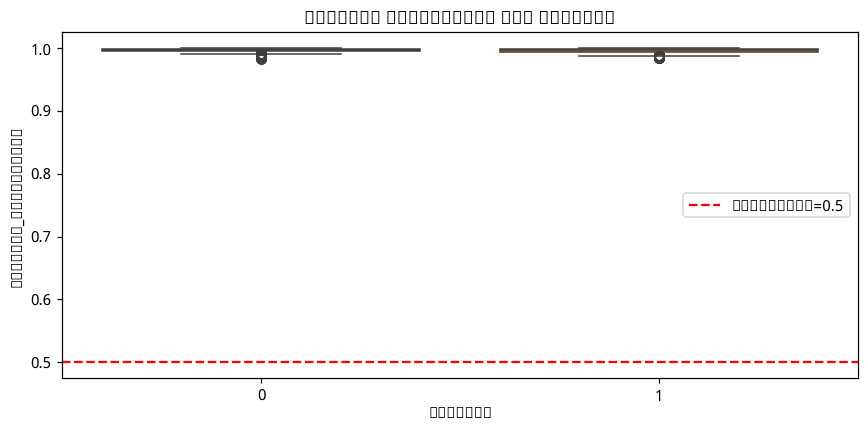

In [ ]:
# import numpy as np
# # import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns
# import os
# from sklearn.metrics.pairwise import cosine_similarity

# # --- 1. Compute and Save Similarity Scores if missing ---
# if not os.path.exists("outputs/similarity_scores.csv"):
#     print("Calculating cluster confidence scores...")
#     X = np.load("embeddings/umap_10d.npy")
#     df = pd.read_csv("outputs/clusters.csv")
#     cluster_ids = sorted(df["cluster"].unique())

#     # Calculate centroid for each cluster and find similarity for each item
#     confidences = np.zeros(len(df))
#     for c in cluster_ids:
#         idx = np.where(df["cluster"].values == c)[0]
#         Xc = X[idx]
#         center = Xc.mean(axis=0, keepdims=True)
#         sims = cosine_similarity(Xc, center).ravel()
#         confidences[idx] = sims

#     df_sim = df.copy()
#     df_sim["cluster_confidence"] = confidences
#     os.makedirs("outputs", exist_ok=True)
#     df_sim.to_csv("outputs/similarity_scores.csv", index=False)
#     print("✅ Saved outputs/similarity_scores.csv")

# # --- 2. Load and Analyze ---
# sim_scores = pd.read_csv("outputs/similarity_scores.csv")

# conf_stats = (sim_scores.groupby("cluster")["cluster_confidence"]
#               .agg(["mean", "median", "std", "min", "max", "count"]
#               ).round(4))
# print("\nCluster Confidence Stats:")
# print(conf_stats.to_string())

# # --- 3. Plot Boxplot ---
# plt.figure(figsize=(8, 4))
# sns.boxplot(data=sim_scores, x="cluster", y="cluster_confidence",
#             palette="tab10")
# plt.axhline(0.5, color="red", linestyle="--", label="threshold=0.5")
# plt.title("Cluster Confidence per Cluster")
# plt.legend()
# plt.tight_layout()
# os.makedirs("figures", exist_ok=True)
# plt.savefig("figures/cluster_confidence_box.png", dpi=250)
# plt.show()

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# Recalculate confidences for the current 4 clusters to keep everything in sync
confidences = np.zeros(len(df))
for c in cluster_ids:
    idx = np.where(df["cluster"].values == c)[0]
    Xc = X[idx]
    center = Xc.mean(axis=0, keepdims=True)
    sims = cosine_similarity(Xc, center).ravel()
    confidences[idx] = sims

df_sim = df.copy()
df_sim["cluster_confidence"] = confidences

# Compute current conf_stats dynamically
current_conf_stats = (df_sim.groupby("cluster")["cluster_confidence"]
                      .agg(["mean", "median", "std", "min", "max", "count"])
                      .round(4))

# Merge coherence and current_conf_stats
summary = coherence.merge(
    current_conf_stats.reset_index(),
    on="cluster"
).round(4)

# Define centroids and sim_matrix
centroids = np.vstack([X[df["cluster"].values == c].mean(axis=0)
                       for c in cluster_ids])
sim_matrix = cosine_similarity(centroids)

# Inter-cluster avg similarity (excluding self)
inter_rows = []
for c in cluster_ids:
    row = sim_matrix[cluster_ids.index(c)].copy()
    row = np.delete(row, cluster_ids.index(c))  # Exclude self-similarity
    inter_rows.append(row.mean())

summary["avg_inter_cluster_sim"] = [round(x, 4) for x in inter_rows]

print("\n📊 FINAL CLUSTER SIMILARITY SUMMARY")
print("="*100)
print(summary.to_string(index=False))
summary.to_csv("outputs/cluster_similarity_summary.csv", index=False)


📊 FINAL CLUSTER SIMILARITY SUMMARY
 cluster  size  mean_sim_to_centroid  min_sim_to_centroid  std_sim_to_centroid  avg_pairwise_similarity  low_conf(<0.5)   mean  median    std    min    max  count  avg_inter_cluster_sim
       0  2149                0.9977               0.9909               0.0016                   0.9954               0 0.9977  0.9980 0.0016 0.9909 1.0000   2149                 0.9853
       1  3052                0.9975               0.9898               0.0014                   0.9950               0 0.9975  0.9977 0.0014 0.9898 0.9999   3052                 0.9816
       2  2485                0.9980               0.9939               0.0011                   0.9961               0 0.9980  0.9981 0.0011 0.9939 1.0000   2485                 0.9841
       3  3271                0.9976               0.9931               0.0013                   0.9952               0 0.9976  0.9978 0.0013 0.9931 0.9999   3271                 0.9893


Inter-Cluster Centroid Similarity (cosine):
       C0     C1     C2     C3
C0  1.000  0.982  0.989  0.985
C1  0.982  1.000  0.972  0.991
C2  0.989  0.972  1.000  0.992
C3  0.985  0.991  0.992  1.000

Color range: vmin=0.952  vmax=1.000
Off-diagonal min=0.972  max=0.992  mean=0.985


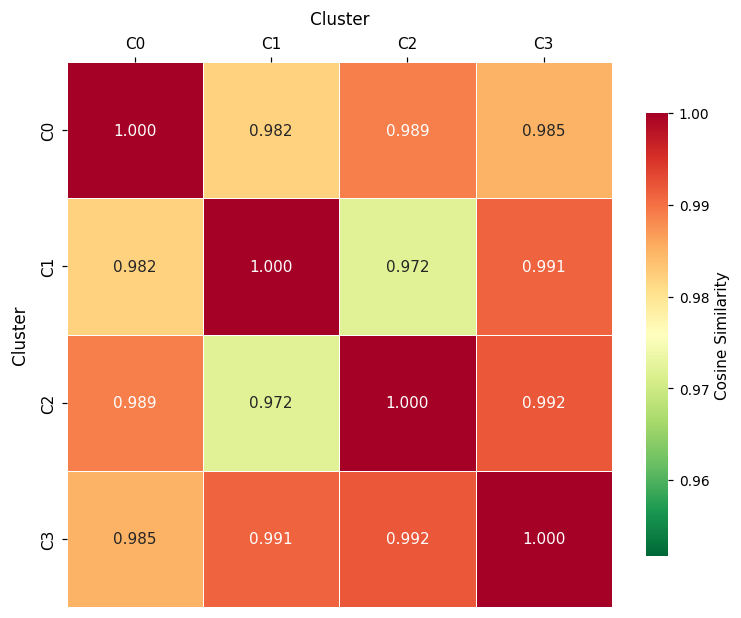


✅ Saved: figures/cluster_similarity_matrix.png  (90.9 KB)


In [ ]:
import numpy as np, pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import seaborn as sns
import os

# --- Global matplotlib settings ---
%matplotlib inline
plt.rcParams['figure.dpi'] = 110
plt.rcParams['savefig.dpi'] = 250
plt.rcParams['axes.unicode_minus'] = False

# Use English-safe font
plt.rcParams['font.family'] = 'DejaVu Sans'

os.makedirs("figures", exist_ok=True)

# --- Load data ---
X  = np.load("embeddings/umap_10d.npy")
df = pd.read_csv("outputs/clusters.csv")

cluster_ids = sorted(df["cluster"].unique())
centroids = np.vstack([X[df["cluster"].values == c].mean(axis=0)
                       for c in cluster_ids])

sim_matrix = cosine_similarity(centroids)

# --- Color scale: focus on actual off-diagonal range ---
off_diag = sim_matrix[~np.eye(len(cluster_ids), dtype=bool)]
vmin = max(0.0, off_diag.min() - 0.02)
vmax = 1.0

sim_df = pd.DataFrame(
    np.round(sim_matrix, 3),
    index=[f"C{c}" for c in cluster_ids],
    columns=[f"C{c}" for c in cluster_ids],
)

print("Inter-Cluster Centroid Similarity (cosine):")
print(sim_df.to_string())
print(f"\nColor range: vmin={vmin:.3f}  vmax={vmax:.3f}")
print(f"Off-diagonal min={off_diag.min():.3f}  "
      f"max={off_diag.max():.3f}  mean={off_diag.mean():.3f}")

# --- Heatmap with English-tuned font sizes ---
fig, ax = plt.subplots(figsize=(7, 6))   # slightly smaller since English is compact

sns.heatmap(
    sim_df,
    annot=True,
    fmt=".3f",
    cmap="RdYlGn_r",
    vmin=vmin, vmax=vmax,
    square=True,
    linewidths=0.6,
    linecolor="white",
    annot_kws={"size": 10, "weight": "normal"},   # 12 -> 10 for English
    cbar_kws={"label": "Cosine Similarity", "shrink": 0.75},
    ax=ax,
)

# # Title & axis labels (English sizes)
# ax.set_title("Inter-Cluster Centroid Similarity",
#              fontsize=13, pad=12, fontweight="bold")
ax.set_xlabel("Cluster", fontsize=11, labelpad=8)
ax.set_ylabel("Cluster", fontsize=11, labelpad=8)

# Tick labels
ax.tick_params(axis='both', labelsize=10)

# Colorbar label font
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=9)
cbar.set_label("Cosine Similarity", fontsize=10)

# Place X labels on top
ax.xaxis.tick_top()
ax.xaxis.set_label_position('top')

plt.tight_layout()
plt.savefig("figures/cluster_similarity_matrix.png",
            dpi=250, bbox_inches="tight", facecolor="white")
plt.show()

# --- Verify file saved ---
p = "figures/cluster_similarity_matrix.png"
print(f"\n✅ Saved: {p}  ({os.path.getsize(p)/1024:.1f} KB)")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


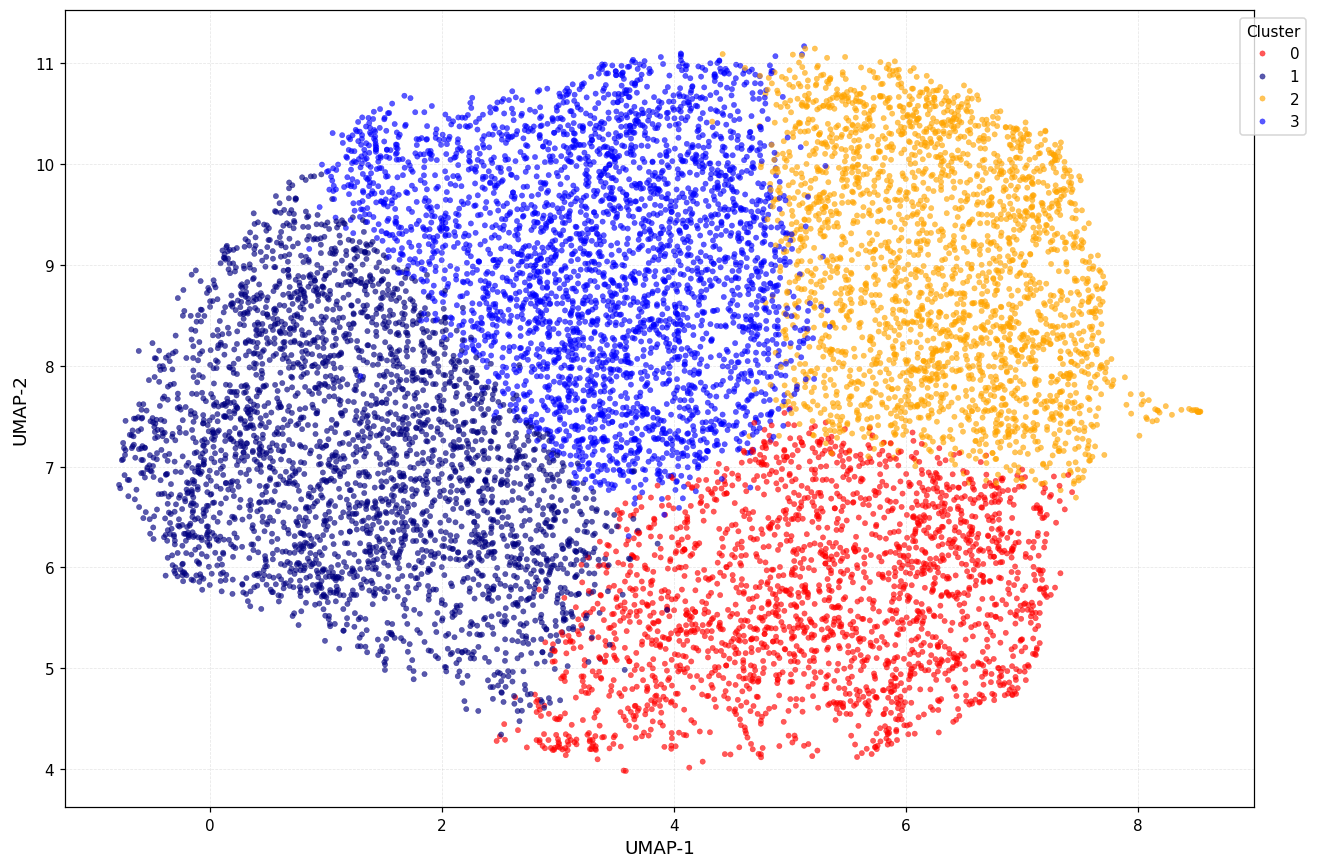

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("figures", exist_ok=True)

# Load 2D UMAP embeddings and cluster assignments
Z = np.load("embeddings/umap_2d.npy")
df = pd.read_csv("outputs/clusters.csv")

# ------------------------------------------------------------
# Custom cluster colors
# ------------------------------------------------------------
cluster_colors = {
    0: "red",
    1: "navy",
    2: "orange",
    3: "blue"
}

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
plt.figure(figsize=(12, 8))

sns.scatterplot(
    x=Z[:, 0],
    y=Z[:, 1],
    hue=df["cluster"],
    palette=cluster_colors,
    s=12,
    alpha=0.65,
    edgecolor=None
)

# English title
# plt.title(
#     "2D UMAP Visualization of Discovered Clusters",
#     fontsize=16,
#     fontweight="bold",
#     pad=12
# )

plt.xlabel("UMAP-1", fontsize=12)
plt.ylabel("UMAP-2", fontsize=12)

plt.legend(
    title="Cluster",
    bbox_to_anchor=(1.05, 1),
    loc="upper right"
)

plt.grid(
    alpha=0.3,
    linestyle="--",
    linewidth=0.5
)

plt.tight_layout()

# High-resolution output
plt.savefig(
    "figures/umap_clusters_2d.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

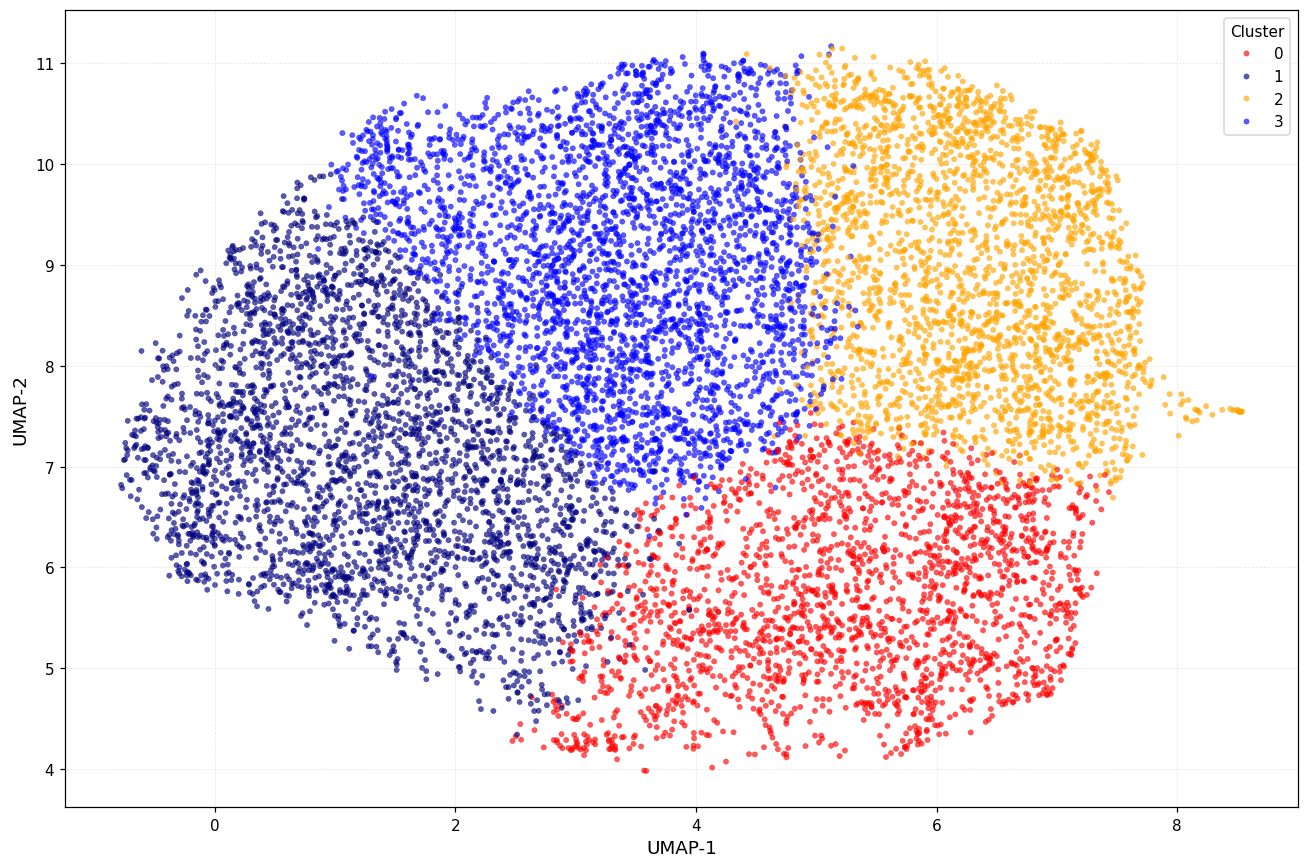

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("figures", exist_ok=True)

# Load 2D UMAP embeddings and cluster assignments
Z = np.load("embeddings/umap_2d.npy")
df = pd.read_csv("outputs/clusters.csv")

cluster_colors = {
    0: "red",
    1: "navy",
    2: "orange",
    3: "blue"
}

plt.figure(figsize=(12, 8))

sns.scatterplot(
    x=Z[:, 0],
    y=Z[:, 1],
    hue=df["cluster"],
    palette=cluster_colors,
    s=12,
    alpha=0.65,
    edgecolor=None
)

plt.xlabel("UMAP-1", fontsize=12)
plt.ylabel("UMAP-2", fontsize=12)

# Place the legend inside the plot box on the upper right
plt.legend(
    title="Cluster",
    loc="upper right"
)

plt.grid(
    alpha=0.3,
    linestyle="--",
    linewidth=0.5
)

plt.tight_layout()

# High-resolution output
plt.savefig(
    "figures/umap_clusters_2d.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Load 10D UMAP embeddings and cluster labels
X = np.load("embeddings/umap_10d.npy")
df = pd.read_csv("outputs/clusters.csv")
labels = df["cluster"].values

# Calculate evaluation metrics
sil = silhouette_score(X, labels)
db = davies_bouldin_score(X, labels)
ch = calinski_harabasz_score(X, labels)

print("\n✨ Quantitative Cluster Validation")
print("="*40)
print(f"Silhouette Score:          {sil:.4f} (higher is better)")
print(f"Davies-Bouldin Score:      {db:.4f} (lower is better)")
print(f"Calinski-Harabasz Score:   {ch:.1f} (higher is better)")


✨ Quantitative Cluster Validation
Silhouette Score:          0.3518 (higher is better)
Davies-Bouldin Score:      0.9578 (lower is better)
Calinski-Harabasz Score:   8714.0 (higher is better)


In [ ]:
# The inter-cluster similarity and centroid separation analysis has already been performed in a previous cell.
# Please refer to the output of cell `VXOHp-fuYDvW` which contains the 'Inter-Cluster Centroid Similarity' heatmap and table.